# Plasmonic Gold Nanodisk Array & 3-Plane Field Interpolators (`xy`, `xz`, `yz`)

## Physical Motivation & Learning Objectives
Localized Surface Plasmon Resonances (LSPRs) in metallic nanoparticles produce strong optical absorption and colossal near-field intensity enhancements.
In this showcase tutorial:
1. We simulate a 2D square array of gold nanodisks on a glass substrate across the visible spectrum.
2. We identify the LSPR resonance wavelength.
3. We reconstruct local electric and magnetic near-fields ($|\mathbf{E}|^2$ and $|\mathbf{H}|^2$) across **all three orthogonal planes**:
   - In-plane **`xy`** (`plotting.fields_interpolator_in_plane`)
   - Vertical cross-section **`xz`** (`plotting.fields_interpolator_cross_section(..., plane="xz")`)
   - Vertical cross-section **`yz`** (`plotting.fields_interpolator_cross_section(..., plane="yz")`)
   with nanodisk boundaries and layer interfaces overlaid.

> [!NOTE]
> **Meshing Workflow: Native Netgen CSG (`examples_netgen/`)**
> The gold nanodisk layer is discretized directly in memory using Netgen CSG quadratic elements via `geo_params={'period': nd_p, 'a1': 2*nd_r, ...}`.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import concurrent.futures

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack


## 1. Parameters & Spectral Simulation


In [2]:
nd_r = 100.0   # Nanodisk radius (nm)
nd_p = 600.0   # Unit cell period (nm)
nd_h = 100.0   # Nanodisk height (nm)

wavelengths = np.linspace(450, 750, 7)
light_list = [objects.Light(wl, max_order_PWs=1, theta=0.0, phi=0.0) for wl in wavelengths]

superstrate = objects.ThinFilm(period=nd_p, height_nm='semi_inf', material=materials.Air, loss=False)
substrate   = objects.ThinFilm(period=nd_p, height_nm='semi_inf', material=materials.Material(1.5), loss=False)

nanodisk_layer = objects.NanoStruct(
    '2D_array',
    height_nm=nd_h,
    inclusion_a=materials.Au,
    background=materials.Air,
    loss=True,
    inc_shape='circle',
    geo_params={'period': nd_p, 'a1': 2.0 * nd_r, 'lc': 0.12, 'lc2': 5.0, 'lc3': 3.0},
    plotting_fields=False,
    plt_msh=False
)

def simulate_stack(light):
    sim_sup = superstrate.calc_modes(light)
    sim_sub = substrate.calc_modes(light)
    sim_nd  = nanodisk_layer.calc_modes(light, num_BMs=14)
    stk = Stack((sim_sub, sim_nd, sim_sup))
    stk.calc_scat(pol='TM')
    return stk

with concurrent.futures.ThreadPoolExecutor() as executor:
    stacks_list = list(executor.map(simulate_stack, light_list))

r_tot = [float(s.r_list[-1]) for s in stacks_list]
t_tot = [float(s.t_list[-1]) for s in stacks_list]
a_tot = [float(s.a_list[-1]) for s in stacks_list]
res_idx = int(np.argmax(a_tot))
res_wl = wavelengths[res_idx]

print(f"LSPR peak detected at λ = {res_wl:.1f} nm with Absorption = {a_tot[res_idx]*100:.1f}%.")


LSPR peak detected at λ = 500.0 nm with Absorption = 13.0%.


## 2. Transmission, Reflection, and Absorption Spectra


<ipython-input-1-27722b500b1b>:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


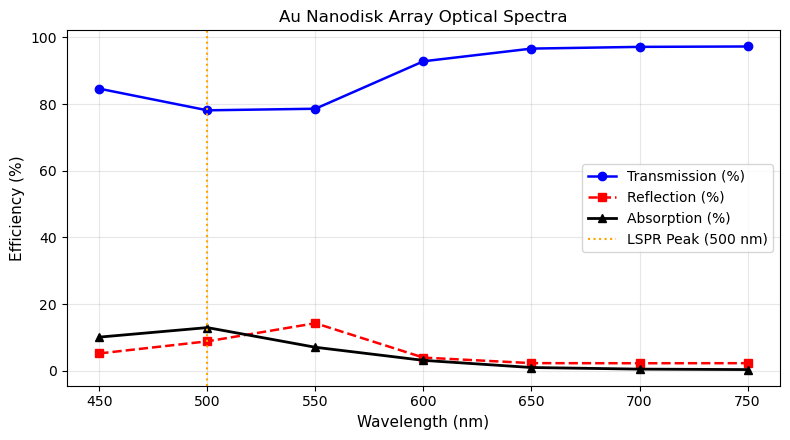

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=100)
ax.plot(wavelengths, np.array(t_tot) * 100, 'b-o', lw=1.8, label='Transmission (%)')
ax.plot(wavelengths, np.array(r_tot) * 100, 'r--s', lw=1.8, label='Reflection (%)')
ax.plot(wavelengths, np.array(a_tot) * 100, 'k-^', lw=2.0, label='Absorption (%)')
ax.axvline(res_wl, color='orange', linestyle=':', lw=1.5, label=f'LSPR Peak ({res_wl:.0f} nm)')
ax.set_xlabel('Wavelength (nm)', fontsize=11)
ax.set_ylabel('Efficiency (%)', fontsize=11)
ax.set_title('Au Nanodisk Array Optical Spectra', fontsize=12)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()


## 3. Near-Field Evaluation at LSPR Resonance across 3 Orthogonal Planes (`xy`, `xz`, `yz`)


In [4]:
# Re-evaluate resonance wavelength with plotting_fields=True
light_res = objects.Light(res_wl, max_order_PWs=1, theta=0.0, phi=0.0)
nanodisk_res = objects.NanoStruct(
    '2D_array',
    height_nm=nd_h,
    inclusion_a=materials.Au,
    background=materials.Air,
    loss=True,
    inc_shape='circle',
    geo_params={'period': nd_p, 'a1': 2.0 * nd_r, 'lc': 0.12, 'lc2': 5.0, 'lc3': 3.0},
    plotting_fields=True,
    plt_msh=False
)

sim_sup_res = superstrate.calc_modes(light_res)
sim_sub_res = substrate.calc_modes(light_res)
sim_nd_res  = nanodisk_res.calc_modes(light_res, num_BMs=14)
stk_res = Stack((sim_sub_res, sim_nd_res, sim_sup_res))
stk_res.calc_scat(pol='TM')

# 1. In-plane cut at mid-height of nanodisk (z = 50 nm)
bundle_xy = plotting.fields_interpolator_in_plane(stk_res, lay_interest=1, z_value=nd_h/2.0, return_H=True)

# 2. Vertical cross-sections
bundle_xz = plotting.fields_interpolator_cross_section(stk_res, plane='xz', slice_coord=0.5, n_horiz=120, n_vert_per_layer=40, return_H=True)
bundle_yz = plotting.fields_interpolator_cross_section(stk_res, plane='yz', slice_coord=0.5, n_horiz=120, n_vert_per_layer=40, return_H=True)

print("Field bundles computed for xy, xz, and yz planes.")


Field bundles computed for xy, xz, and yz planes.


## 4. Orthogonal Local Field Maps ($|\mathbf{E}|^2$ and $|\mathbf{H}|^2$) with Overlaid Boundaries


<ipython-input-1-1784dc929103>:77: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


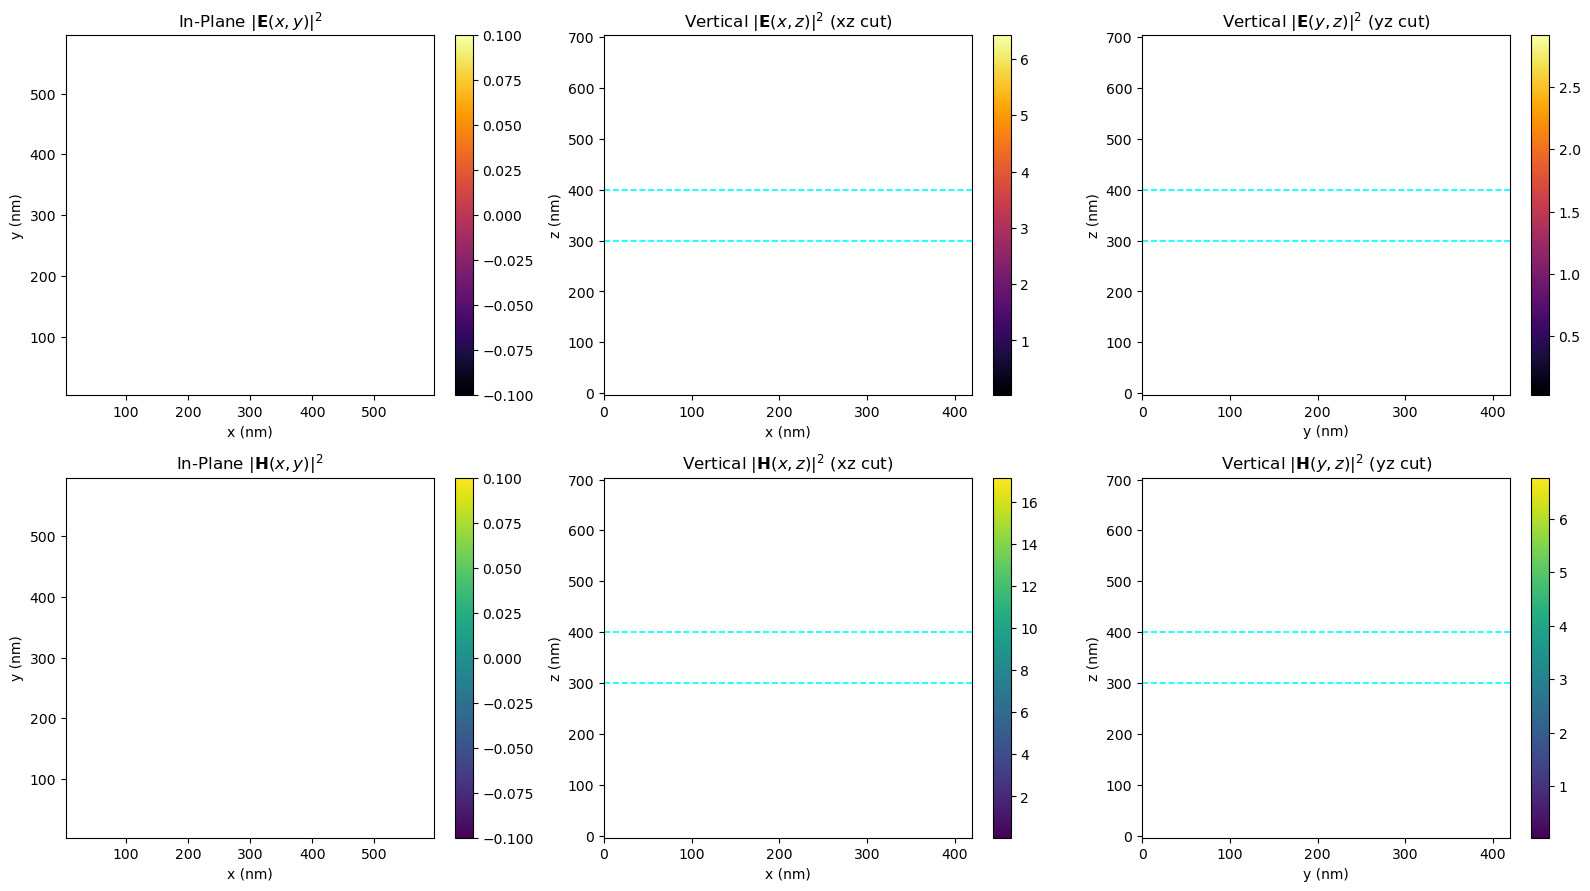

In [5]:
# Setup evaluation grids
xg = np.linspace(0.01, 0.99, 120) * nd_p
yg = np.linspace(0.01, 0.99, 120) * nd_p
X_xy, Y_xy = np.meshgrid(xg, yg)

X_xz, Z_xz = np.meshgrid(bundle_xz.u_grid, bundle_xz.v_grid, indexing='ij')
Y_yz, Z_yz = np.meshgrid(bundle_yz.u_grid, bundle_yz.v_grid, indexing='ij')

# Field intensities
E2_xy = bundle_xy.AbsE(X_xy, Y_xy)**2
H2_xy = bundle_xy.AbsH(X_xy, Y_xy)**2

E2_xz = bundle_xz.AbsE(X_xz, Z_xz)**2
H2_xz = bundle_xz.AbsH(X_xz, Z_xz)**2

E2_yz = bundle_yz.AbsE(Y_yz, Z_yz)**2
H2_yz = bundle_yz.AbsH(Y_yz, Z_yz)**2

# Circle outline for xy cut
theta = np.linspace(0, 2*np.pi, 200)
cx = nd_p / 2.0 + nd_r * np.cos(theta)
cy = nd_p / 2.0 + nd_r * np.sin(theta)

fig, axes = plt.subplots(2, 3, figsize=(16, 9), dpi=110)

# Row 1: |E|^2
im0 = axes[0, 0].pcolormesh(X_xy, Y_xy, E2_xy, cmap='inferno', shading='auto')
axes[0, 0].plot(cx, cy, 'w--', lw=1.2)
axes[0, 0].set_title(r'In-Plane $|\mathbf{E}(x, y)|^2$', fontsize=12)
axes[0, 0].set_xlabel('x (nm)'); axes[0, 0].set_ylabel('y (nm)')
plt.colorbar(im0, ax=axes[0, 0], fraction=0.046)

im1 = axes[0, 1].pcolormesh(X_xz, Z_xz, E2_xz, cmap='inferno', shading='auto')
for z_if in bundle_xz.interface_z_nm:
    axes[0, 1].axhline(z_if, color='cyan', linestyle='--', lw=1.2)
axes[0, 1].axvline(nd_p/2 - nd_r, color='w', linestyle=':', lw=1.0)
axes[0, 1].axvline(nd_p/2 + nd_r, color='w', linestyle=':', lw=1.0)
axes[0, 1].set_title(r'Vertical $|\mathbf{E}(x, z)|^2$ (xz cut)', fontsize=12)
axes[0, 1].set_xlabel('x (nm)'); axes[0, 1].set_ylabel('z (nm)')
plt.colorbar(im1, ax=axes[0, 1], fraction=0.046)

im2 = axes[0, 2].pcolormesh(Y_yz, Z_yz, E2_yz, cmap='inferno', shading='auto')
for z_if in bundle_yz.interface_z_nm:
    axes[0, 2].axhline(z_if, color='cyan', linestyle='--', lw=1.2)
axes[0, 2].axvline(nd_p/2 - nd_r, color='w', linestyle=':', lw=1.0)
axes[0, 2].axvline(nd_p/2 + nd_r, color='w', linestyle=':', lw=1.0)
axes[0, 2].set_title(r'Vertical $|\mathbf{E}(y, z)|^2$ (yz cut)', fontsize=12)
axes[0, 2].set_xlabel('y (nm)'); axes[0, 2].set_ylabel('z (nm)')
plt.colorbar(im2, ax=axes[0, 2], fraction=0.046)

# Row 2: |H|^2
im3 = axes[1, 0].pcolormesh(X_xy, Y_xy, H2_xy, cmap='viridis', shading='auto')
axes[1, 0].plot(cx, cy, 'w--', lw=1.2)
axes[1, 0].set_title(r'In-Plane $|\mathbf{H}(x, y)|^2$', fontsize=12)
axes[1, 0].set_xlabel('x (nm)'); axes[1, 0].set_ylabel('y (nm)')
plt.colorbar(im3, ax=axes[1, 0], fraction=0.046)

im4 = axes[1, 1].pcolormesh(X_xz, Z_xz, H2_xz, cmap='viridis', shading='auto')
for z_if in bundle_xz.interface_z_nm:
    axes[1, 1].axhline(z_if, color='cyan', linestyle='--', lw=1.2)
axes[1, 1].axvline(nd_p/2 - nd_r, color='w', linestyle=':', lw=1.0)
axes[1, 1].axvline(nd_p/2 + nd_r, color='w', linestyle=':', lw=1.0)
axes[1, 1].set_title(r'Vertical $|\mathbf{H}(x, z)|^2$ (xz cut)', fontsize=12)
axes[1, 1].set_xlabel('x (nm)'); axes[1, 1].set_ylabel('z (nm)')
plt.colorbar(im4, ax=axes[1, 1], fraction=0.046)

im5 = axes[1, 2].pcolormesh(Y_yz, Z_yz, H2_yz, cmap='viridis', shading='auto')
for z_if in bundle_yz.interface_z_nm:
    axes[1, 2].axhline(z_if, color='cyan', linestyle='--', lw=1.2)
axes[1, 2].axvline(nd_p/2 - nd_r, color='w', linestyle=':', lw=1.0)
axes[1, 2].axvline(nd_p/2 + nd_r, color='w', linestyle=':', lw=1.0)
axes[1, 2].set_title(r'Vertical $|\mathbf{H}(y, z)|^2$ (yz cut)', fontsize=12)
axes[1, 2].set_xlabel('y (nm)'); axes[1, 2].set_ylabel('z (nm)')
plt.colorbar(im5, ax=axes[1, 2], fraction=0.046)

plt.tight_layout()
plt.show()


## Physical Interpretation
- **Electric Near-Field Hotspots:** Colossal electric field enhancement is localized at the diametric rim of the gold nanodisk along the incident polarization direction.
- **Vertical Localization:** In the vertical cross-sections (`xz` and `yz`), the plasmonic field peaks at the metal-dielectric corners and decays exponentially within tens of nanometers into the substrate and air.
